Эпизод 1

In [1]:
import pandas as pd

df = pd.read_csv('transactions.csv')

ok = df[df['STATUS'] == 'OK']

print("Топ-3 платежа (OK):")
print(ok.nlargest(3, 'SUM')[['CONTRACTOR', 'SUM']].to_string(index=False))

total = ok[ok['CONTRACTOR'] == 'Umbrella, Inc']['SUM'].sum()
print(f"\nСумма платежей в адрес Umbrella, Inc (OK): {total}")

Топ-3 платежа (OK):
   CONTRACTOR    SUM
    Acme, Inc 100500
Umbrella, Inc   1000
    Acme, Inc    999

Сумма платежей в адрес Umbrella, Inc (OK): 925719


Эпизод 2

 CARGO  flights  total_price  total_weight
 Jumbo       50        76795         18709
Medium      100        36312          9507
Nimble      500       752588          7545


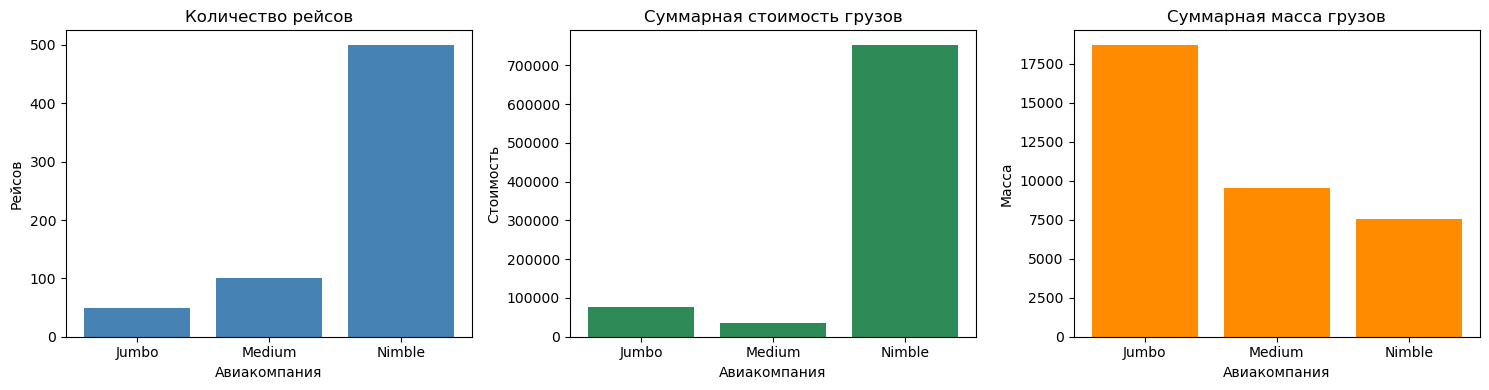

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('flights.csv')

stats = df.groupby('CARGO').agg(
    flights=('PRICE', 'count'),
    total_price=('PRICE', 'sum'),
    total_weight=('WEIGHT', 'sum')
).reset_index()

print(stats.to_string(index=False))



fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(stats['CARGO'], stats['flights'], color='steelblue')
axes[0].set_title('Количество рейсов')
axes[0].set_xlabel('Авиакомпания')
axes[0].set_ylabel('Рейсов')

axes[1].bar(stats['CARGO'], stats['total_price'], color='seagreen')
axes[1].set_title('Суммарная стоимость грузов')
axes[1].set_xlabel('Авиакомпания')
axes[1].set_ylabel('Стоимость')

axes[2].bar(stats['CARGO'], stats['total_weight'], color='darkorange')
axes[2].set_title('Суммарная масса грузов')
axes[2].set_xlabel('Авиакомпания')
axes[2].set_ylabel('Масса')

plt.tight_layout()
plt.savefig('flights_stats.png', dpi=150)
plt.show()

Эпизод 3

/tmp/ipykernel_6929/1223816742.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results['G'] = results['G'].apply(to_num)
/tmp/ipykernel_6929/1223816742.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results['H'] = results['H'].apply(to_num)


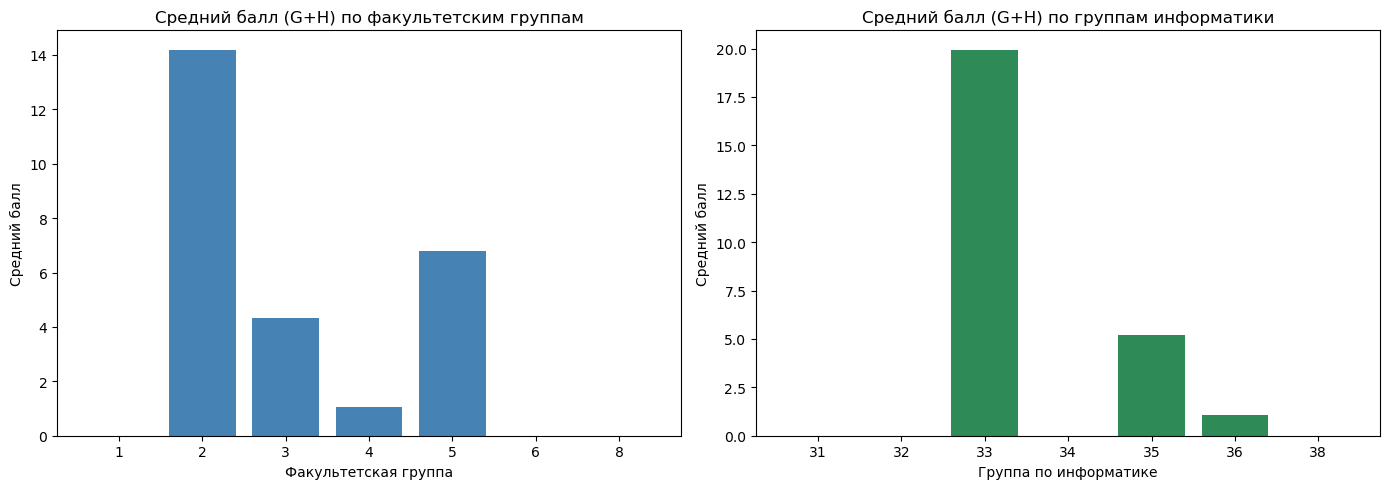

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_excel('students_info.xlsx', sheet_name='logins')
students = students.dropna(subset=['login'])

tables = pd.read_html('results_ejudge.html')
results = tables[0][['User', 'G', 'H']]
results.columns = ['login', 'G', 'H']

def to_num(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return 0.0

results['G'] = results['G'].apply(to_num)
results['H'] = results['H'].apply(to_num)

merged = students.merge(results, on='login', how='left')
merged['G'] = merged['G'].fillna(0)
merged['H'] = merged['H'].fillna(0)
merged['solved'] = merged['G'] + merged['H']

by_faculty = merged.groupby('group_faculty')['solved'].mean()
by_out = merged.groupby('group_out')['solved'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(by_faculty.index.astype(str), by_faculty.values, color='steelblue')
axes[0].set_title('Средний балл (G+H) по факультетским группам')
axes[0].set_xlabel('Факультетская группа')
axes[0].set_ylabel('Средний балл')

axes[1].bar(by_out.index.astype(str), by_out.values, color='seagreen')
axes[1].set_title('Средний балл (G+H) по группам информатики')
axes[1].set_xlabel('Группа по информатике')
axes[1].set_ylabel('Средний балл')

plt.tight_layout()
plt.savefig('avg_scores.png', dpi=150)
plt.show()

target = merged[(merged['G'] >= 20) | (merged['H'] >= 20)]

with open('task2_result.txt', 'w', encoding='utf-8') as f:
    f.write("Логины, прошедшие >1 теста в G или H:\n")
    f.write(target[['login', 'group_faculty', 'group_out', 'G', 'H']].to_string(index=False))
    f.write("\n\nФакультетские группы:\n")
    f.write(str(sorted(target['group_faculty'].unique().tolist())))
    f.write("\n\nГруппы по информатике:\n")
    f.write(str(sorted(target['group_out'].unique().tolist())))
    f.write("\n")

Текст task2_result.txt:

Логины, прошедшие >1 теста в G или H:
   login  group_faculty  group_out    G    H
r0300205              2         33 30.0 49.0
r0300206              2         33 30.0 49.0
r0300209              2         33  0.0 30.0
r0300212              2         36  0.0 20.0
r0300301              3         35  8.0 23.0
r0300314              3         33  9.0 20.0
r0300508              5         33 29.0  0.0
r0300511              5         35  0.0 29.0
r0300514              5         33  0.0 30.0
r0300515              5         35  0.0 25.0

Факультетские группы:
[2, 3, 5]

Группы по информатике:
[33, 35, 36]
